# Menghitung Volume Kedua Lambung Perahu Katamaran

**Nama:** Andina Maulidiasaputri

**Nim:** 25083010003

**Kelas:** A083 Analisis Numerik

**Sumber gambar:** *Desain dan Konstruksi Perahu Katamaran Fiberglass untuk Wisata Pancing* (ResearchGate, publikasi 342077926).

**Pertanyaan:** Hitung volume kedua lambung kapal, tanpa menghitung volume *reserve buoyancy*.


## 1. Soal, data, dan ketentuan

**Data yang diberikan** adalah gambar katamaran berupa *tampak atas* dan *tampak samping*, ditumpuk dengan grid hijau putus-putus. Kedua tampak digambar sejajar, sehingga garis grid vertikal yang sama menunjukkan posisi memanjang yang sama pada kedua tampak.

**Ketentuan dari soal:**
1. Satu *dash + kosong* pada garis grid = 5 cm + 5 cm = **10 cm**. Ini dipakai sebagai pembanding skala; untuk perhitungan, ukuran **1 kotak grid ditetapkan 45 cm** (= 4,5 periode dash).
2. Dasar kapal dianggap datar (tanpa keel), sehingga **tampak depan semuanya persegi panjang**. Soal tidak menggambar tampak depan, jadi ketentuan ini menggantikannya: bentuk penampang melintang di setiap titik diketahui, yaitu persegi panjang.
3. Volume ***reserve buoyancy* tidak dihitung**, yaitu bagian ujung buritan (kiri) dan haluan (kanan).

**Yang dicari:** volume dua lambung (keduanya terlihat identik).

## 2. Landasan perhitungan

**Penampang persegi panjang.** Pada posisi memanjang $x$, penampang melintang satu lambung berbentuk persegi panjang dengan lebar $b(x)$ dan tinggi $h(x)$, sehingga luasnya

$$A(x) = b(x)\cdot h(x)$$

- $b(x)$ dibaca dari **tampak atas** (lebar lambung).
- $h(x)$ dibaca dari **tampak samping** (jarak dari garis geladak sampai dasar lambung).

**Volume = integral luas penampang sepanjang lambung.** Karena $b$ dan $h$ berubah di sepanjang lambung (meruncing di ujung), volume tidak bisa dihitung sebagai satu balok. Dipakai integral:

$$V = \int_0^L A(x)\,dx$$

**Integrasi numerik.** Data dibaca pada stasiun-stasiun berjarak sama $\Delta x$, lalu diintegrasikan dengan dua metode sebagai pembanding:

- Aturan trapesium: $\displaystyle V \approx \sum_{i=0}^{n-1} \frac{A_i + A_{i+1}}{2}\,\Delta x$
- Aturan Simpson 1/3 (n genap): $\displaystyle V \approx \frac{\Delta x}{3}\Big[A_0 + 4\sum A_{ganjil} + 2\sum A_{genap} + A_n\Big]$

**Dua lambung identik**, sehingga $V_{total} = 2V$.

**Konversi skala.** Gambar terbaca dalam piksel, sehingga diperlukan faktor

$$\text{cm per piksel} = \frac{45\ \text{cm}}{\text{jarak satu kotak grid (piksel)}}$$

## 3. Rencana langkah

1. Menentukan skala gambar (piksel → cm).
2. Menentukan batas bagian utama lambung (di luar *reserve buoyancy*).
3. Membaca lebar $b$ dan kedalaman $h$ pada stasiun-stasiun.
4. Menambal titik lebar yang tertutup balok penyangga (interpolasi).
5. Mengubah satuan piksel ke meter.
6. Menghitung luas penampang $A = b\cdot h$ di tiap stasiun.
7. Mengintegrasikan $A(x)$ (trapesium dan Simpson).
8. Menghitung volume satu dan dua lambung.
9. Memvisualisasikan hasil.
10. Memvalidasi hasil (batas atas, kecocokan metode, kewajaran skala).
11. Menghitung parameter bentuk dan sumbangan tiap bagian lambung.
12. Menguji sensitivitas hasil.
13. (Tambahan) Menghitung perpindahan air terhadap sarat.
14. Kesimpulan dan keterbatasan.

### Persiapan
Mengimpor library: `numpy` untuk hitungan, `pandas` untuk tabel, `matplotlib` untuk grafik, dan `scipy` hanya untuk memeriksa hasil Simpson manual.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import simpson as scipy_simpson   # hanya untuk cross-check hasil Simpson manual

pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("Library siap dipakai.")

Library siap dipakai.


## Langkah 1. Menentukan skala gambar

**Masalah:** semua ukuran di gambar adalah piksel, padahal volume diminta dalam satuan nyata. Diperlukan faktor konversi piksel → cm.

**Skala yang dipakai:** satu kotak grid ditetapkan **45 cm**. Karena jarak antar garis grid terukur dari PDF, faktor konversinya langsung didapat:

$$\text{cm per piksel} = \frac{45\ \text{cm}}{71{,}175\ \text{px}} \approx 0{,}632\ \text{cm/px}$$

**Pengukuran dari PDF** (dirender pada 200 dpi, piksel hijau/grid dideteksi):
- *Jarak antar garis grid* = rata-rata selisih posisi 21 garis grid vertikal ≈ **71,175 px**.
- *Panjang satu periode dash* (dash + kosong = 10 cm menurut soal) ≈ **16,7 px**. Nilai ini hanya dipakai sebagai pembanding: bila skala diturunkan dari dash, 1 kotak ≈ 42,6 cm.

Di sini nilai hasil pengukuran itu dipakai langsung.


In [28]:
# --- Hasil pengukuran dari PDF ---
DASH_PERIOD_PX = 16.7      # panjang 1 periode (dash + kosong) dalam piksel pada render 200 dpi
CELL_PX        = 71.175    # jarak antar dua garis grid (1 kotak) dalam piksel
DASH_CM        = 5 + 5     # dari soal: 1 dash + 1 kosong = 5 cm + 5 cm = 10 cm

# --- Skala yang DIPAKAI: 1 kotak grid ditetapkan = 45 cm ---
CELL_CM       = 45.0                         # panjang 1 kotak dalam cm (ditetapkan)
CM_PER_PX     = CELL_CM / CELL_PX            # berapa cm untuk tiap 1 piksel
DASH_PER_CELL = CELL_CM / DASH_CM            # berapa periode dash dalam 1 kotak (45 cm / 10 cm)

print(f"1 piksel        = {CM_PER_PX:.4f} cm")
print(f"1 kotak grid    = {DASH_PER_CELL:.2f} periode dash")
print(f"1 kotak grid    = {CELL_CM:.1f} cm = {CELL_CM/100:.3f} m")

# Pembanding: skala yang diturunkan dari pengukuran dash (10 cm / 16,7 px)
CELL_CM_DASH = CELL_PX * DASH_CM / DASH_PERIOD_PX
rasio = (CELL_CM / CELL_CM_DASH) ** 3 - 1
print(f"\nSkala dari pengukuran dash  : 1 kotak = {CELL_CM_DASH:.1f} cm")
print(f"Dibanding skala dash, volume berubah {rasio*100:+.1f} %  (volume ~ skala^3)")


1 piksel        = 0.6322 cm
1 kotak grid    = 4.50 periode dash
1 kotak grid    = 45.0 cm = 0.450 m

Skala dari pengukuran dash  : 1 kotak = 42.6 cm
Dibanding skala dash, volume berubah +17.7 %  (volume ~ skala^3)


**Interpretasi.**
- Satu piksel setara 0,632 cm, dan **satu kotak grid = 45 cm = 4,5 periode dash**.
- Skala 45 cm ini 5,6 % lebih besar daripada skala hasil pengukuran dash (42,6 cm). Karena volume berbanding lurus dengan **pangkat tiga** skala, volume menjadi sekitar 17,7 % lebih besar dibanding skala dash.
- Karena itu skala tetap menjadi sumber ketidakpastian terbesar, dan ditinjau lagi di Langkah 12.


## Langkah 2. Menentukan batas bagian utama lambung

*Reserve buoyancy* adalah bagian ujung lambung (buritan di kiri, haluan di kanan, diberi label pada gambar) yang berfungsi sebagai cadangan daya apung. Batasnya ditandai garis lengkung tipis vertikal pada tampak atas. Kebetulan, kedua garis itu jatuh tepat pada garis grid:

- batas kiri = garis grid **kolom 2**,
- batas kanan = garis grid **kolom 18** (garis grid terluar kiri dihitung kolom 0).

Jadi bagian yang dihitung membentang **16 kotak**, dari kolom 2 sampai kolom 18. Bagian di luarnya tidak dihitung, sesuai ketentuan soal.

**Interpretasi.** Batas yang jatuh tepat di garis grid menguntungkan: tidak perlu menebak posisi, dan stasiun pembacaan bisa dimulai tepat di batas. Jika batas dianggap bergeser ½ kotak, pengaruhnya dihitung di Langkah 12.

## Langkah 3. Membaca lebar dan kedalaman pada stasiun

**Stasiun** adalah posisi memanjang tempat $b$ dan $h$ dibaca. Dipilih tiap **½ kotak**, dari kolom 2 sampai 18: 33 stasiun, 32 interval. Jumlah interval genap, sehingga Simpson 1/3 bisa dipakai.

**Cara membaca:**
- **Lebar $b$ (tampak atas).** Diukur dari sumbu tengah lambung sampai tepi luar, lalu dikali 2 (lambung simetris). Pengukuran memakai lambung bawah karena lambung atas tertimpa label teks. Sumbu tengah ditentukan dari tengah lambung (kolom 8).
- **Kedalaman $h$ (tampak samping).** Dari garis geladak sampai dasar lambung, pada garis grid vertikal yang sama.

Hasil pembacaan (dalam piksel):

In [29]:
nan = np.nan

# kolom_grid : posisi stasiun, dihitung dari garis grid terluar kiri (= 0), satuan "kotak"
# b_px       : lebar satu lambung di tampak atas (piksel); NaN = tertutup balok penyangga
# h_px       : kedalaman lambung di tampak samping, dari garis geladak ke dasar (piksel)
raw = np.array([
    [ 2.0, 123, 137], [ 2.5, 131, 151], [ 3.0, 135, 163], [ 3.5, nan, 173],
    [ 4.0, 143, 182], [ 4.5, 145, 187], [ 5.0, 149, 187], [ 5.5, 149, 187],
    [ 6.0, 151, 187], [ 6.5, 151, 187], [ 7.0, 151, 187], [ 7.5, 151, 187],
    [ 8.0, 151, 187], [ 8.5, 151, 187], [ 9.0, 151, 187], [ 9.5, 151, 187],
    [10.0, 151, 186], [10.5, 151, 187], [11.0, 151, 186], [11.5, 151, 186],
    [12.0, 151, 186], [12.5, 151, 186], [13.0, 149, 186], [13.5, 149, 186],
    [14.0, 147, 186], [14.5, nan, 186], [15.0, 141, 186], [15.5, 135, 186],
    [16.0, 131, 186], [16.5, 123, 186], [17.0, 115, 186], [17.5, 105, 185],
    [18.0,  93, 185],
])
df = pd.DataFrame(raw, columns=["kolom_grid", "b_px", "h_px"])
df.index.name = "stasiun"

print(f"Jumlah stasiun  : {len(df)}")
print(f"Jumlah interval : {len(df) - 1}  (genap -> aturan Simpson 1/3 bisa dipakai)")
print(f"Jarak stasiun   : {df.kolom_grid.diff().dropna().unique()} kotak")
display(df.head(8))
display(df.tail(5))

Jumlah stasiun  : 33
Jumlah interval : 32  (genap -> aturan Simpson 1/3 bisa dipakai)
Jarak stasiun   : [0.5] kotak


,kolom_grid,b_px,h_px
stasiun,,,
0,2.000,123.000,137.000
1,2.500,131.000,151.000
2,3.000,135.000,163.000
3,3.500,NaN,173.000
4,4.000,143.000,182.000
5,4.500,145.000,187.000
6,5.000,149.000,187.000
7,5.500,149.000,187.000


,kolom_grid,b_px,h_px
stasiun,,,
28,16.000,131.000,186.000
29,16.500,123.000,186.000
30,17.000,115.000,186.000
31,17.500,105.000,185.000
32,18.000,93.000,185.000


**Interpretasi.**
- Bagian tengah (kolom ±6 sampai ±12,5) hampir konstan: lebar 151 px dan kedalaman 186 sampai 187 px. Lambung di sana berbentuk **balok lurus (prismatik)**.
- Menuju kedua ujung, lebar menyempit (151 → 123 px di kiri, 151 → 93 px di kanan). Kedalaman ujung kiri turun cepat (187 → 137 px) karena dasar lambung melengkung naik di buritan. Di ujung kanan, kedalaman hampir tetap sampai kolom 18; pada tampak samping, dasar haluan baru naik di luar bagian yang dihitung (setelah kolom 18).
- Ada dua nilai lebar kosong (`NaN`) di kolom 3,5 dan 14,5: di titik itu tepi lambung tertutup balok penyangga melintang.

## Langkah 4. Menambal titik yang tertutup balok penyangga

Lebar di kolom 3,5 dan 14,5 tidak bisa dibaca karena tertutup balok. Karena lebar berubah mulus di sepanjang lambung, nilai yang hilang diisi dengan **interpolasi linear** dari dua stasiun tetangganya.

In [30]:
df["b_px_asli"] = df["b_px"]
tertutup = df["b_px"].isna()
print("Stasiun yang lebarnya tertutup balok penyangga (kolom grid):", df.loc[tertutup, "kolom_grid"].tolist())

# interpolasi linear dari dua tetangga terdekat yang terbaca
df["b_px"] = np.interp(df["kolom_grid"], df.loc[~tertutup, "kolom_grid"], df.loc[~tertutup, "b_px"])

dekat = sorted({i + d for i in df.index[tertutup] for d in (-1, 0, 1)})
display(df.loc[dekat, ["kolom_grid", "b_px_asli", "b_px"]])
print("Masih ada data kosong?", df[["b_px", "h_px"]].isna().any().any())

Stasiun yang lebarnya tertutup balok penyangga (kolom grid): [3.5, 14.5]


,kolom_grid,b_px_asli,b_px
stasiun,,,
2,3.000,135.000,135.000
3,3.500,NaN,139.000
4,4.000,143.000,143.000
24,14.000,147.000,147.000
25,14.500,NaN,144.000
26,15.000,141.000,141.000


Masih ada data kosong? False


**Interpretasi.** Nilai hasil interpolasi (139 dan 144 px) berada di antara tetangganya dan mengikuti kecenderungan lebar di sekitarnya, jadi wajar. Karena hanya 2 dari 33 stasiun dan lebar di sana berubah landai, galat akibat penambalan ini sangat kecil.

## Langkah 5. Mengubah satuan piksel ke meter

Dengan faktor skala dari Langkah 1:

$$x = (\text{kolom} - 2)\times \text{ukuran kotak},\qquad b = b_{px}\times \text{cm/px},\qquad h = h_{px}\times \text{cm/px}$$

lalu dibagi 100 agar menjadi meter. Posisi $x = 0$ ditetapkan di batas kiri bagian utama (kolom 2).

In [31]:
# posisi memanjang x diukur dari ujung kiri bagian utama lambung
df["x_m"] = (df["kolom_grid"] - df["kolom_grid"].iloc[0]) * CELL_CM / 100   # m
df["b_m"] = df["b_px"] * CM_PER_PX / 100                                    # m
df["h_m"] = df["h_px"] * CM_PER_PX / 100                                    # m

display(df[["kolom_grid", "b_px", "h_px", "x_m", "b_m", "h_m"]])
print(f"\nPanjang bagian utama L = {df.x_m.iloc[-1]:.3f} m")
print(f"Lebar maksimum     B = {df.b_m.max():.3f} m")
print(f"Kedalaman maksimum D = {df.h_m.max():.3f} m")

,kolom_grid,b_px,h_px,x_m,b_m,h_m
stasiun,,,,,,
0,2.000,123.000,137.000,0.000,0.778,0.866
1,2.500,131.000,151.000,0.225,0.828,0.955
2,3.000,135.000,163.000,0.450,0.854,1.031
3,3.500,139.000,173.000,0.675,0.879,1.094
4,4.000,143.000,182.000,0.900,0.904,1.151
5,4.500,145.000,187.000,1.125,0.917,1.182
6,5.000,149.000,187.000,1.350,0.942,1.182
7,5.500,149.000,187.000,1.575,0.942,1.182
8,6.000,151.000,187.000,1.800,0.955,1.182



Panjang bagian utama L = 7.200 m
Lebar maksimum     B = 0.955 m
Kedalaman maksimum D = 1.182 m


**Interpretasi.** Bagian utama lambung panjangnya sekitar 7,20 m, lebar maksimum 0,95 m, dan dalam 1,18 m. Perbandingannya (panjang jauh lebih besar dari lebar) cocok dengan bentuk lambung katamaran yang ramping.

## Langkah 6. Menghitung luas penampang tiap stasiun

Karena penampang persegi panjang, luasnya tinggal hasil kali lebar dan kedalaman: $A = b\cdot h$ (m²).

In [32]:
# Penampang melintang = persegi panjang  ->  A = lebar x kedalaman
df["A_m2"] = df["b_m"] * df["h_m"]

display(df[["kolom_grid", "x_m", "b_m", "h_m", "A_m2"]].iloc[[0, 2, 4, 6, 8, 16, 24, 26, 28, 30, 32]])
print(f"\nLuas penampang maksimum : {df.A_m2.max():.4f} m^2")
print(f"Luas penampang di ujung kiri  : {df.A_m2.iloc[0]:.4f} m^2")
print(f"Luas penampang di ujung kanan : {df.A_m2.iloc[-1]:.4f} m^2")

,kolom_grid,x_m,b_m,h_m,A_m2
stasiun,,,,,
0,2.000,0.000,0.778,0.866,0.674
2,3.000,0.450,0.854,1.031,0.880
4,4.000,0.900,0.904,1.151,1.040
6,5.000,1.350,0.942,1.182,1.114
8,6.000,1.800,0.955,1.182,1.129
16,10.000,3.600,0.955,1.176,1.123
24,14.000,5.400,0.929,1.176,1.093
26,15.000,5.850,0.891,1.176,1.048
28,16.000,6.300,0.828,1.176,0.974



Luas penampang maksimum : 1.1287 m^2
Luas penampang di ujung kiri  : 0.6736 m^2
Luas penampang di ujung kanan : 0.6877 m^2


**Interpretasi.**
- Luas penampang paling besar (1,129 m²) terjadi di bagian tengah, yaitu $B\times D$.
- Di ujung kiri luasnya turun menjadi 0,674 m² (lebar sempit dan dasar naik), di ujung kanan menjadi 0,688 m² (hanya lebar yang menyempit).
- Jadi volume terkumpul terutama di bagian tengah. Hal ini dibuktikan angka pada Langkah 11.

## Langkah 7. Mengintegrasikan luas penampang

Volume satu lambung = $\int A(x)\,dx$. Dihitung dengan dua metode, lalu hasil Simpson manual dibandingkan dengan fungsi `scipy`.

- Trapesium menganggap $A(x)$ lurus di antara dua stasiun.
- Simpson 1/3 menganggap $A(x)$ melengkung (parabola) di antara tiga stasiun, sehingga lebih teliti untuk bentuk yang melengkung.

In [33]:
x = df["x_m"].to_numpy()
b = df["b_m"].to_numpy()
h = df["h_m"].to_numpy()
A = df["A_m2"].to_numpy()

n  = len(x) - 1                  # jumlah interval
dx = x[1] - x[0]                 # jarak antar stasiun (m)
assert np.allclose(np.diff(x), dx), "stasiun harus berjarak sama untuk Simpson"
assert n % 2 == 0, "jumlah interval harus genap untuk Simpson 1/3"
print(f"n = {n} interval, dx = {dx:.4f} m\n")

# ---------- (a) Aturan trapesium ----------
dV = (A[1:] + A[:-1]) / 2 * np.diff(x)       # volume tiap potongan (m^3)
V_trap = dV.sum()

# ---------- (b) Aturan Simpson 1/3, dirinci ----------
A_awal, A_akhir = A[0], A[-1]
jumlah_ganjil = A[1:-1:2].sum()              # stasiun ke-1, 3, 5, ...  (dikali 4)
jumlah_genap  = A[2:-1:2].sum()              # stasiun ke-2, 4, 6, ...  (dikali 2)
V_simp = dx / 3 * (A_awal + 4 * jumlah_ganjil + 2 * jumlah_genap + A_akhir)

print("Rincian Simpson:")
print(f"  A awal            = {A_awal:.4f}")
print(f"  A akhir           = {A_akhir:.4f}")
print(f"  jumlah A ganjil   = {jumlah_ganjil:.4f}   (x4 = {4*jumlah_ganjil:.4f})")
print(f"  jumlah A genap    = {jumlah_genap:.4f}   (x2 = {2*jumlah_genap:.4f})")
print(f"  V = dx/3 * (...)  = {V_simp:.4f} m^3\n")

# ---------- (c) Cross-check dengan library ----------
V_scipy = scipy_simpson(A, x=x)

print(f"Trapesium            : {V_trap:.4f} m^3")
print(f"Simpson (manual)     : {V_simp:.4f} m^3")
print(f"Simpson (scipy)      : {V_scipy:.4f} m^3")
print(f"Selisih trapesium vs Simpson: {abs(V_trap - V_simp) / V_simp * 100:.3f} %")
print(f"Manual vs scipy cocok? {np.isclose(V_simp, V_scipy)}")

n = 32 interval, dx = 0.2250 m

Rincian Simpson:
  A awal            = 0.6736
  A akhir           = 0.6877
  jumlah A ganjil   = 16.7118   (x4 = 66.8472)
  jumlah A genap    = 15.9948   (x2 = 31.9897)
  V = dx/3 * (...)  = 7.5149 m^3

Trapesium            : 7.5121 m^3
Simpson (manual)     : 7.5149 m^3
Simpson (scipy)      : 7.5149 m^3
Selisih trapesium vs Simpson: 0.036 %
Manual vs scipy cocok? True


**Interpretasi.**
- Kedua metode memberi volume satu lambung yang praktis sama (7,512 vs 7,515 m³, selisih 0,04 %). Artinya jarak stasiun ½ kotak sudah cukup halus, dan hasil tidak bergantung pada pilihan metode.
- Simpson manual sama dengan `scipy`, sehingga rumus yang ditulis sudah benar.
- Hasil Simpson dipakai selanjutnya karena umumnya lebih teliti.

## Langkah 8. Volume satu dan dua lambung

Kedua lambung pada gambar identik (dicek di Langkah 10), sehingga

$$V_{dua\ lambung} = 2 \times V_{satu\ lambung}$$

In [34]:
V_satu = V_simp            # m^3, satu lambung
V_dua  = 2 * V_satu        # m^3, dua lambung identik

print(f"Volume SATU lambung  : {V_satu:.3f} m^3 = {V_satu*1000:,.0f} liter")
print(f"Volume DUA lambung   : {V_dua:.3f} m^3 = {V_dua*1000:,.0f} liter")

Volume SATU lambung  : 7.515 m^3 = 7,515 liter
Volume DUA lambung   : 15.030 m^3 = 15,030 liter


**Interpretasi.** Volume dua lambung bagian utama adalah **15,03 m³ ≈ 15.030 liter**. Angka ini adalah volume geometris luar sampai garis geladak, tanpa *reserve buoyancy* dan tanpa mengurangi tebal dinding fiberglass.

## Langkah 9. Visualisasi

Grafik dipakai untuk memeriksa apakah hasil digitisasi mirip gambar aslinya dan apakah $A(x)$ mulus.

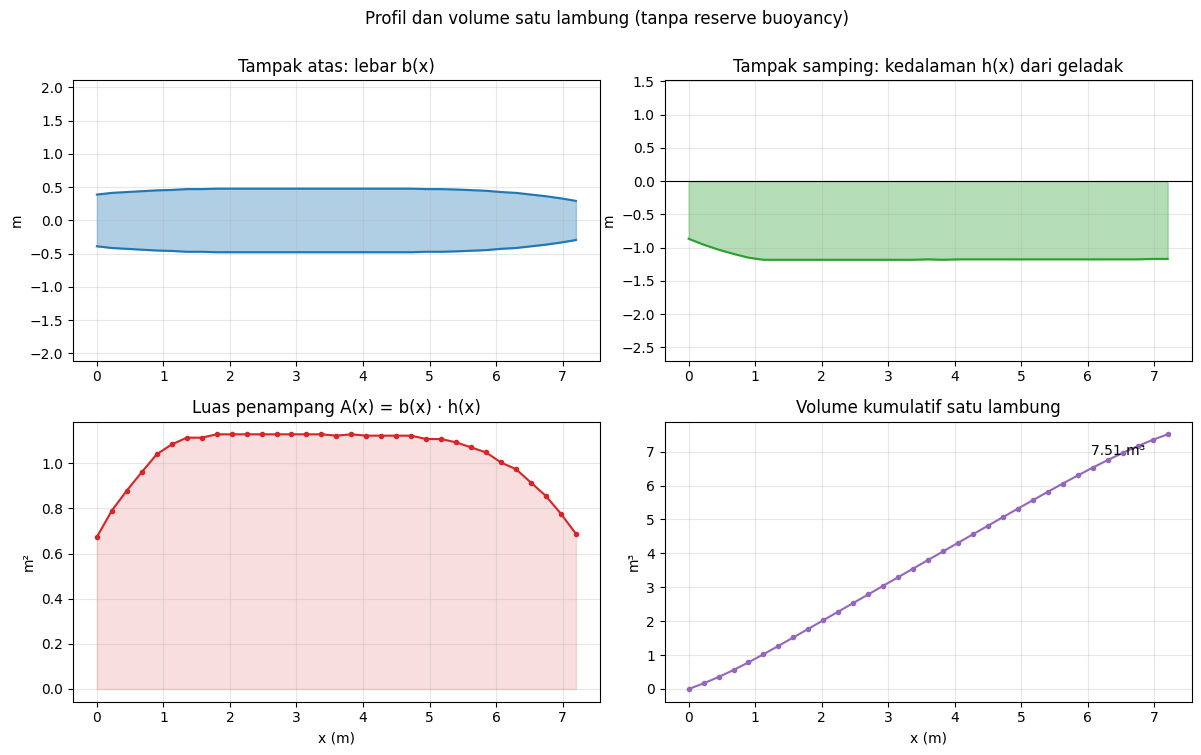

In [35]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))

# (1) tampak atas
a = ax[0, 0]
a.fill_between(x, b/2, -b/2, color="tab:blue", alpha=.35); a.plot(x, b/2, "tab:blue"); a.plot(x, -b/2, "tab:blue")
a.set_title("Tampak atas: lebar b(x)"); a.set_ylabel("m"); a.set_aspect("equal", adjustable="datalim")

# (2) tampak samping
a = ax[0, 1]
a.fill_between(x, 0, -h, color="tab:green", alpha=.35); a.plot(x, -h, "tab:green"); a.axhline(0, color="k", lw=.8)
a.set_title("Tampak samping: kedalaman h(x) dari geladak"); a.set_ylabel("m"); a.set_aspect("equal", adjustable="datalim")

# (3) luas penampang
a = ax[1, 0]
a.plot(x, A, "tab:red", marker="o", ms=3); a.fill_between(x, A, color="tab:red", alpha=.15)
a.set_title("Luas penampang A(x) = b(x) · h(x)"); a.set_xlabel("x (m)"); a.set_ylabel("m²")

# (4) volume kumulatif
a = ax[1, 1]
V_kum = np.concatenate([[0], np.cumsum(dV)])
a.plot(x, V_kum, "tab:purple", marker="o", ms=3)
a.set_title("Volume kumulatif satu lambung"); a.set_xlabel("x (m)"); a.set_ylabel("m³")
a.annotate(f"{V_trap:.2f} m³", (x[-1], V_kum[-1]), textcoords="offset points", xytext=(-55, -15))

fig.suptitle("Profil dan volume satu lambung (tanpa reserve buoyancy)", y=1.0)
plt.tight_layout(); plt.show()

**Interpretasi.**
- *Tampak atas* dan *tampak samping* hasil digitisasi mirip gambar asli: bagian tengah lurus, ujung meruncing.
- Kurva $A(x)$ naik cepat di ujung kiri, mendatar di tengah, lalu turun di ujung kanan, tidak ada lonjakan tak wajar. Berarti tidak ada kesalahan baca besar.
- Volume kumulatif hampir **linear** di bagian tengah (bentuk balok lurus: penambahan volume per meter konstan) dan melandai di kedua ujung.

## Langkah 10. Validasi hasil

Beberapa pemeriksaan agar hasil dapat dipercaya:
1. Volume lambung harus lebih kecil dari balok penuh $L\times B\times D$.
2. Dua lambung harus benar-benar identik.
3. Dua metode integrasi harus sepakat.
4. Ukuran hasil skala harus masuk akal untuk perahu pancing wisata.

In [36]:
L, B, D = x[-1], b.max(), h.max()

# (1) batas atas: balok penuh L x B x D
V_balok = L * B * D
print(f"Balok penuh L x B x D = {L:.3f} x {B:.3f} x {D:.3f} = {V_balok:.3f} m^3")
print(f"Volume lambung / balok = {V_satu / V_balok:.3f}  (harus < 1)")

# (2) apakah dua lambung benar-benar identik? (lebar tengah yang diukur terpisah di tampak atas)
lebar_atas, lebar_bawah = 152, 151        # piksel, di kolom grid 6-12
print(f"\nLebar tengah lambung atas vs bawah: {lebar_atas} px vs {lebar_bawah} px "
      f"-> beda {abs(lebar_atas-lebar_bawah)/lebar_bawah*100:.1f} %  (identik, V_total = 2 x V_satu)")

# (3) pengecekan skala: panjang kapal total (termasuk reserve buoyancy) harus masuk akal
print(f"\nPanjang bagian utama saja: {L:.2f} m; lebar lambung {B:.2f} m; kedalaman {D:.2f} m")

# (4) selisih dua metode integrasi
print(f"Trapesium vs Simpson beda {abs(V_trap-V_simp)/V_simp*100:.3f} % -> diskretisasi 1/2 kotak sudah cukup halus")

Balok penuh L x B x D = 7.200 x 0.955 x 1.182 = 8.127 m^3
Volume lambung / balok = 0.925  (harus < 1)

Lebar tengah lambung atas vs bawah: 152 px vs 151 px -> beda 0.7 %  (identik, V_total = 2 x V_satu)

Panjang bagian utama saja: 7.20 m; lebar lambung 0.95 m; kedalaman 1.18 m
Trapesium vs Simpson beda 0.036 % -> diskretisasi 1/2 kotak sudah cukup halus


**Interpretasi.**
- Volume lambung = 0,92 kali balok penuh, jadi < 1 seperti seharusnya. Sisanya adalah ruang yang hilang akibat meruncingnya kedua ujung.
- Lebar lambung atas dan bawah hanya berbeda ±0,7 %, jadi pemakaian $V_{total}=2V$ sah.
- Dua metode integrasi sepakat sampai 0,04 %.
- Kewajaran skala: panjang total gambar lambung (termasuk *reserve buoyancy*) ≈ 9,5 m (perkiraan dari skala 45 cm per kotak), lebar satu lambung 0,95 m, dan jarak antar pusat lambung sekitar 3,2 m. Ukuran ini sesuai dengan perahu katamaran pancing yang memuat beberapa orang. Seandainya satu kotak hanya 10 cm, kapal akan sepanjang sekitar 2 m dan tiap lambung selebar 0,2 m: terlalu kecil untuk perahu wisata.

## Langkah 11. Parameter bentuk dan sumbangan tiap bagian lambung

Parameter bentuk membantu menafsirkan hasil:

| Parameter | Rumus | Arti |
|---|---|---|
| $L/B$ | panjang / lebar | seberapa ramping lambung |
| $B/D$ | lebar / dalam | proporsi penampang |
| $C_b$ | $V/(L\,B\,D)$ | seberapa penuh lambung dibanding balok |
| $C_p$ | $V/(A_{maks}\,L)$ | seberapa penuh lambung dibanding prisma dengan penampang tengah |
| $C_m$ | $A_{maks}/(B\,D)$ | seberapa penuh penampang tengah |

Lambung juga dibagi tiga (ujung kiri, tengah, ujung kanan) untuk melihat sumbangan volumenya.

In [37]:
A_max = A.max()
Cb = V_satu / (L * B * D)            # koefisien blok
Cp = V_satu / (A_max * L)            # koefisien prismatik (A_max = luas penampang tengah)
Cm = A_max / (B * D)                 # koefisien penampang tengah
LB = L / B
BD = B / D

print(f"L/B = {LB:.2f}    B/D = {BD:.2f}")
print(f"Cb = {Cb:.3f}    Cp = {Cp:.3f}    Cm = {Cm:.3f}")

# sumbangan tiap bagian lambung terhadap volume
kolom = df["kolom_grid"].to_numpy()
tengah_xy = (kolom[1:] + kolom[:-1]) / 2
bagian = np.where(tengah_xy < 5, "ujung kiri (kolom 2-5)",
          np.where(tengah_xy > 13, "ujung kanan (kolom 13-18)", "tengah (kolom 5-13)"))
seg = (pd.DataFrame({"bagian": bagian, "panjang_m": np.diff(x), "V_m3": dV})
         .groupby("bagian", sort=False).sum())
seg["% panjang"] = seg["panjang_m"] / L * 100
seg["% volume"]  = seg["V_m3"] / V_satu * 100
display(seg)

L/B = 7.54    B/D = 0.81
Cb = 0.925    Cp = 0.925    Cm = 1.000


,panjang_m,V_m3,% panjang,% volume
bagian,,,,
ujung kiri (kolom 2-5),1.350,1.271,18.750,16.915
tengah (kolom 5-13),3.600,4.049,50.000,53.883
ujung kanan (kolom 13-18),2.250,2.192,31.250,29.166


**Interpretasi.**
- $L/B \approx$ 7,5: lambung **sangat ramping**, khas katamaran. Lambung ramping memberi hambatan gelombang kecil, sehingga perahu lebih mudah dipacu.
- $C_m = 1$ karena penampang dianggap persegi panjang tanpa keel/bilga. Akibatnya $C_b = C_p \approx$ 0,92. Nilai setinggi itu tidak realistis untuk lambung nyata, yang berpenampang V atau U (biasanya $C_m$ sekitar 0,7 sampai 0,9). Jadi volume sebenarnya akan lebih kecil dari hasil ini, dan hasil ini adalah **batas atas** akibat asumsi soal.
- Bagian tengah (3,60 m, 50 % panjang) menyumbang 54 % volume. Dua ujung yang meruncing menyumbang sisanya, masing-masing sekitar 17 % (kiri) dan 29 % (kanan). Kesalahan baca di bagian tengah karenanya paling berpengaruh pada hasil.

## Langkah 12. Sensitivitas hasil

Hasil dari gambar tidak persis. Sensitivitas menunjukkan seberapa jauh volume berubah jika pembacaan meleset sedikit:
- skala ±1 % (kesalahan mengukur periode dash),
- lebar ±3 px (garis lambung digambar ganda, tebal ±3 px),
- kedalaman ±9 px (ketebalan garis geladak),
- batas *reserve buoyancy* digeser ½ kotak ke dalam di kedua ujung.

Volume acuan: 15.030 m^3



,V_dua_lambung (m3),selisih (m3),selisih (%)
Skala -1 %,14.583,-0.446,-2.970
Skala +1 %,15.485,0.455,3.030
Lebar -3 px (garis tebal),14.713,-0.316,-2.106
Lebar +3 px,15.346,0.316,2.106
Kedalaman -9 px (garis geladak),14.293,-0.737,-4.904
Kedalaman +9 px,15.767,0.737,4.904
Batas reserve digeser 1/2 kotak ke dalam,14.375,-0.654,-4.354


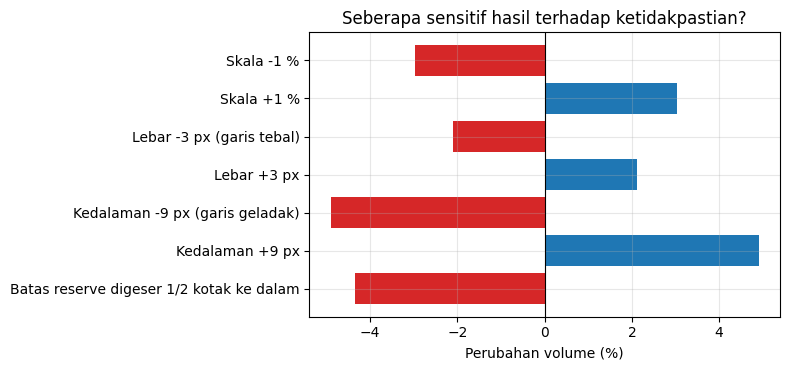

In [38]:
def V_dua_lambung(skala=1.0, db=0.0, dh=0.0, idx=slice(None)):
    """Volume dua lambung. skala: pengali skala; db, dh: koreksi piksel pada lebar dan kedalaman."""
    k   = CM_PER_PX * skala / 100                      # m per piksel
    xx  = (df["kolom_grid"].to_numpy()[idx] - 2.0) * CELL_PX * k
    bb  = (df["b_px"].to_numpy()[idx] + db) * k
    hh  = (df["h_px"].to_numpy()[idx] + dh) * k
    return 2 * scipy_simpson(bb * hh, x=xx)

V0 = V_dua_lambung()
skenario = {
    "Skala -1 %":                     V_dua_lambung(skala=0.99),
    "Skala +1 %":                     V_dua_lambung(skala=1.01),
    "Lebar -3 px (garis tebal)":      V_dua_lambung(db=-3),
    "Lebar +3 px":                    V_dua_lambung(db=+3),
    "Kedalaman -9 px (garis geladak)": V_dua_lambung(dh=-9),
    "Kedalaman +9 px":                V_dua_lambung(dh=+9),
    "Batas reserve digeser 1/2 kotak ke dalam": V_dua_lambung(idx=slice(1, -1)),
}
sens = pd.DataFrame({"V_dua_lambung (m3)": skenario}).assign(**{
    "selisih (m3)": lambda d: d.iloc[:, 0] - V0,
    "selisih (%)":  lambda d: (d.iloc[:, 0] / V0 - 1) * 100,
})
print(f"Volume acuan: {V0:.3f} m^3\n")
display(sens)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(sens.index, sens["selisih (%)"], color=["tab:red" if v < 0 else "tab:blue" for v in sens["selisih (%)"]])
ax.axvline(0, color="k", lw=.8); ax.invert_yaxis()
ax.set_xlabel("Perubahan volume (%)"); ax.set_title("Seberapa sensitif hasil terhadap ketidakpastian?")
plt.tight_layout(); plt.show()

**Interpretasi.**
- **Skala ±1 %** mengubah volume sekitar ±3 %, karena volume ~ skala³. Ini bukti bahwa ketelitian skala sangat menentukan.
- **Kedalaman ±9 px** memberi pengaruh paling besar (±4,9 %), karena garis geladak cukup tebal dan menentukan titik acuan kedalaman.
- **Lebar ±3 px** memberi ±2,1 %.
- **Menggeser batas reserve buoyancy ½ kotak** ke dalam mengurangi volume 4,4 %, sehingga posisi batas ini ikut mempengaruhi hasil.
- Menggabungkan galat skala, lebar, dan kedalaman yang tidak saling berhubungan (dijumlah secara kuadrat), ketidakpastian total sekitar ±6 %. Posisi batas *reserve buoyancy* tidak ikut digabung karena batas itu jatuh tepat pada garis grid; baris terakhir tabel hanya menunjukkan seberapa besar pengaruhnya jika pembaca menempatkannya berbeda. Jadi hasil paling tepat ditulis sebagai **15,03 m³ ± 6 %**, atau rentang 14,1 sampai 15,9 m³.

## Langkah 13 (tambahan). Perpindahan air terhadap sarat

Volume geometris di atas adalah volume *sampai geladak*. Perahu sebenarnya mengapung dengan hanya sebagian lambung tercelup, sehingga berguna juga untuk melihat berapa air yang dipindahkan pada berbagai sarat $T$. Karena dasar lambung naik di ujung, tinggi bagian yang tercelup di tiap stasiun adalah

$$h_{celup}(x) = \text{clip}\big(T - (D - h(x)),\ 0,\ h(x)\big)$$

dan volume tercelup $= 2\int b(x)\,h_{celup}(x)\,dx$. Perpindahan (massa air yang dipindahkan) = volume tercelup × massa jenis air laut (1025 kg/m³).

,sarat T (cm),V tercelup (m3),perpindahan (ton),% dari V total
0,20.000,2.334,2.392,15.526
1,30.000,3.603,3.693,23.975
2,40.000,4.897,5.019,32.581
3,50.000,6.192,6.347,41.199
4,60.000,7.487,7.675,49.817
5,80.000,10.078,10.330,67.053
6,100.000,12.668,12.985,84.289
7,118.230,15.030,15.405,100.000



Luas garis air dua lambung ~ 12.95 m^2
Tambahan beban per 1 cm sarat (TPC) ~ 133 kg/cm


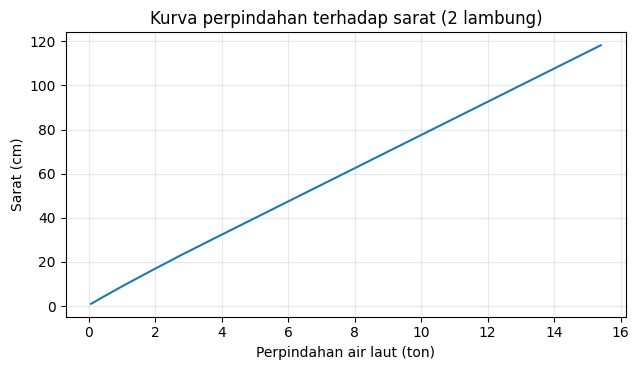

In [39]:
RHO_LAUT = 1025   # kg/m^3

def volume_tercelup(T):
    """Volume dua lambung yang tercelup pada sarat T (m), diukur dari titik terendah dasar lambung."""
    tinggi_dasar = D - h                          # tinggi dasar di atas titik terendah (dasar naik di ujung)
    tercelup = np.clip(T - tinggi_dasar, 0, h)    # tinggi bagian yang berada di bawah air
    return 2 * scipy_simpson(b * tercelup, x=x)

sarat = np.array([0.20, 0.30, 0.40, 0.50, 0.60, 0.80, 1.00, D])
tab = pd.DataFrame({
    "sarat T (cm)":           sarat * 100,
    "V tercelup (m3)":        [volume_tercelup(T) for T in sarat],
})
tab["perpindahan (ton)"] = tab["V tercelup (m3)"] * RHO_LAUT / 1000
tab["% dari V total"]    = tab["V tercelup (m3)"] / V_dua * 100
display(tab)

# luas garis air dua lambung (pendekatan sisi tegak) -> TPC
Awp = 2 * scipy_simpson(b, x=x)
TPC = RHO_LAUT * Awp * 0.01
print(f"\nLuas garis air dua lambung ~ {Awp:.2f} m^2")
print(f"Tambahan beban per 1 cm sarat (TPC) ~ {TPC:.0f} kg/cm")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
Ts = np.linspace(0.01, D, 60)
ax.plot([volume_tercelup(T) * RHO_LAUT / 1000 for T in Ts], Ts * 100)
ax.set_xlabel("Perpindahan air laut (ton)"); ax.set_ylabel("Sarat (cm)")
ax.set_title("Kurva perpindahan terhadap sarat (2 lambung)")
plt.tight_layout(); plt.show()

**Interpretasi.**
- Pada sarat penuh ($T = D$) volume tercelup sama dengan volume total (15,03 m³ = 15,4 ton), pemeriksaan yang cocok.
- Pada sarat 30 cm perpindahannya 3,7 ton, dan pada sarat 50 cm 6,3 ton. Artinya, berat total kapal beserta muatannya yang membuat sarat 30 cm adalah sekitar 3,7 ton.
- Setiap tambahan beban sekitar **133 kg** membuat kapal tenggelam 1 cm, atau sekitar 7,5 cm untuk tiap tambahan 1 ton muatan. Dua lambung memberi luas garis air yang cukup besar (12,95 m²), sehingga penambahan muatan hanya menaikkan sarat secara bertahap.
- Selisih antara perpindahan pada sarat kerja dan perpindahan penuh adalah cadangan daya apung (*reserve buoyancy*) kapal.
- Ini pendekatan: lebar lambung dianggap tetap terhadap sarat (penampang persegi panjang), sedangkan lambung nyata melebar ke atas.

## 14. Hasil, kesimpulan, dan keterbatasan

### Hasil

| Besaran | Nilai |
|---|---|
| Volume satu lambung | **7,51 m³** (7.515 liter) |
| **Volume kedua lambung** | **15,03 m³** (15.030 liter) |
| Rentang (± ketidakpastian) | 14,1 sampai 15,9 m³ |

### Kesimpulan

1. Dengan skala 1 kotak = 45 cm dan penampang persegi panjang, volume **dua lambung** bagian utama (tanpa *reserve buoyancy*) adalah **≈ 15,03 m³** (sekitar 15.030 liter); tiap lambung ≈ 7,51 m³.
2. Volume terkumpul di bagian tengah yang lurus (54 % volume dari 50 % panjang), sedangkan dua ujung yang meruncing menyumbang sisanya.
3. Lambung sangat ramping (L/B ≈ 7,5), khas katamaran, dengan daya apung maksimum teoretis ≈ 15,4 ton bila terendam sampai geladak.
4. Hasil paling peka terhadap skala (volume ~ skala³) dan pembacaan kedalaman; ketidakpastian sekitar ±6 %.

### Keterbatasan

- Data dibaca dari gambar raster hasil pindai (bukan gambar teknik asli), sehingga ada galat baca beberapa piksel.
- Penampang dianggap persegi panjang dan dasar datar (sesuai soal). Pada lambung nyata ada bilga/chine dan dasar melengkung, sehingga volume nyata **lebih kecil** dari hasil ini.
- Tebal dinding fiberglass tidak dikurangkan (yang dihitung volume luar).
- Dua lambung dianggap identik (terbukti dalam batas ±0,7 %).
- Skala 1 kotak = 45 cm ditetapkan sebagai ukuran yang dipakai. Pengukuran dash pada PDF memberi ≈ 42,6 cm; selisih 5,6 % ini membuat volume sekitar 17,7 % lebih besar, jadi ukuran kotak yang sebenarnya perlu dipastikan.